In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
        classification_report,
            confusion_matrix
            )

In [2]:
from google.colab import files

uploaded = files.upload()

Saving SPSIRDATA.csv to SPSIRDATA.csv


In [3]:
df = pd.read_csv("SPSIRDATA.csv")

print("Parking Dataset Shape:", df.shape)

Parking Dataset Shape: (2769, 5)


In [4]:
df.head()

,created_at,entry_id,field1,field2,field3
0,2020-01-01 00:00:00 UTC,1,IR20,1,2000-0-8T45:162:0
1,2020-01-01 08:35:00 UTC,2,IR40,0,2000-0-1T45:162:0
2,2020-01-02 02:12:00 UTC,3,IR22,1,2000-0-4T45:162:0
3,2020-01-02 17:45:00 UTC,4,IR12,0,2000-0-5T45:162:0
4,2020-01-03 05:48:00 UTC,5,IR18,1,2000-0-3T45:162:0


In [5]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2769 entries, 0 to 2768
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   created_at  2769 non-null   object
 1   entry_id    2769 non-null   int64 
 2   field1      2769 non-null   object
 3   field2      2769 non-null   int64 
 4   field3      2769 non-null   object
dtypes: int64(2), object(3)
memory usage: 108.3+ KB
None


In [6]:
print("Columns:")
print(df.columns)

Columns:
Index(['created_at', 'entry_id', 'field1', 'field2', 'field3'], dtype='object')


In [10]:
df["created_at"] = pd.to_datetime(df["created_at"])

df["hour"] = df["created_at"].dt.hour
df["day"] = df["created_at"].dt.day
df["month"] = df["created_at"].dt.month
df["day_of_week"] = df["created_at"].dt.dayofweek

In [11]:
df[["created_at", "hour", "day", "month", "day_of_week"]].head()

,created_at,hour,day,month,day_of_week
0,2020-01-01 00:00:00+00:00,0,1,1,2
1,2020-01-01 08:35:00+00:00,8,1,1,2
2,2020-01-02 02:12:00+00:00,2,2,1,3
3,2020-01-02 17:45:00+00:00,17,2,1,3
4,2020-01-03 05:48:00+00:00,5,3,1,4


In [12]:
df["sensor_id"] = df["field1"].str.extract(r"(\d+)").astype(int)

In [13]:
print(df[["field1", "sensor_id"]].head())

  field1  sensor_id
0   IR20         20
1   IR40         40
2   IR22         22
3   IR12         12
4   IR18         18


In [14]:
print(df["field2"].value_counts())

field2
1    1396
0    1373
Name: count, dtype: int64


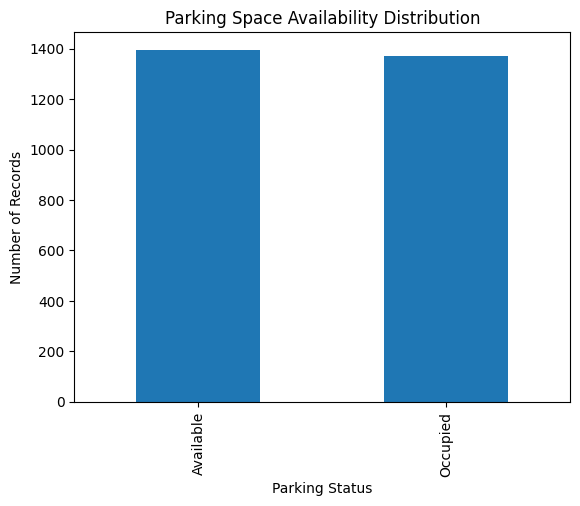

In [16]:
df["field2"].value_counts().plot(kind="bar")

plt.xticks(
    [0, 1],
    ["Available", "Occupied"]
)

plt.xlabel("Parking Status")
plt.ylabel("Number of Records")
plt.title("Parking Space Availability Distribution")

plt.show()

In [18]:
X = df[
      [
         "sensor_id",
         "hour",
         "day",
         "month",
         "day_of_week"
       ]
    ]

y = df["field2"]


In [19]:
print("Input Shape:", X.shape)
print("Output Shape:", y.shape)

Input Shape: (2769, 5)
Output Shape: (2769,)


In [21]:
X_train, X_test, y_train, y_test = train_test_split(
      X,
          y,
              test_size=0.2,
                  random_state=42,
                      stratify=y
                      )


In [22]:
print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (2215, 5)
Testing Data: (554, 5)


In [23]:
model = RandomForestClassifier(
      n_estimators=100,
          random_state=42
     )

model.fit(X_train, y_train)

print("Model Training Completed!")


Model Training Completed!


In [24]:
y_pred = model.predict(X_test)

print("Predictions:")
print(y_pred[:10])

Predictions:
[1 1 1 1 0 1 1 0 1 0]


In [25]:
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")

Model Accuracy: 48.91696750902527 %


In [26]:
print(
      classification_report(
              y_test,
                      y_pred,
                              target_names=["Available", "Occupied"]
                                  )
                                  )


              precision    recall  f1-score   support

   Available       0.49      0.48      0.48       275
    Occupied       0.49      0.49      0.49       279

    accuracy                           0.49       554
   macro avg       0.49      0.49      0.49       554
weighted avg       0.49      0.49      0.49       554



In [27]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[133 142]
 [141 138]]


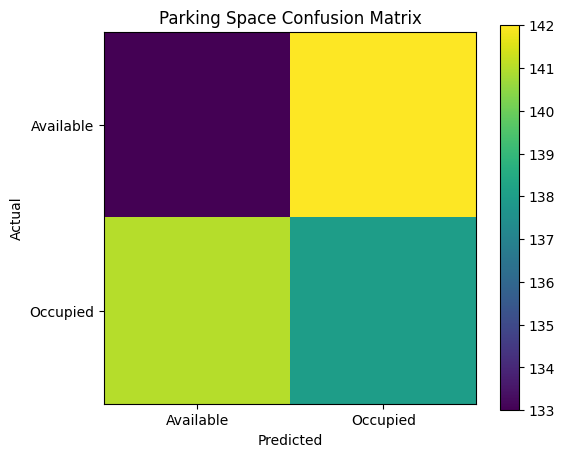

In [28]:
plt.figure(figsize=(6, 5))

plt.imshow(cm)

plt.colorbar()

plt.xticks(
    [0, 1],
        ["Available", "Occupied"]
        )

plt.yticks(
            [0, 1],
                ["Available", "Occupied"]
                )

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.title("Parking Space Confusion Matrix")

plt.show()

In [29]:
def predict_parking(
    sensor_id,
    hour,
    day,
    month,
    day_of_week
):
    new_data = pd.DataFrame({
        "sensor_id": [sensor_id],
        "hour": [hour],
        "day": [day],
        "month": [month],
        "day_of_week": [day_of_week]
    })

    prediction = model.predict(new_data)

    if prediction[0] == 0:
        return "PARKING AVAILABLE"
    else:
        return "PARKING OCCUPIED"

In [30]:
result = predict_parking(
      sensor_id=20,
      hour=10,
      day=15,
      month=6,
      day_of_week=0
     )

print("Prediction:", result)


Prediction: PARKING AVAILABLE
